In [1]:
from sksurv.linear_model import CoxPHSurvivalAnalysis, CoxnetSurvivalAnalysis
from sksurv.nonparametric import kaplan_meier_estimator
from sksurv.compare import compare_survival

import sklearn
from sklearn import set_config
from sklearn.model_selection import GridSearchCV, KFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
set_config(display="text")  # displays text representation of estimators

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import scipy
import os
import gseapy as gp

import warnings
warnings.filterwarnings('ignore')

%matplotlib inline
plt.rcParams['axes.grid'] = False

In [3]:
os.makedirs('output',exist_ok=True)

# Bulk RNA-seq data loading

In [4]:
Discovery_rna = pd.read_csv('../example_data/TCGA_LAML_logTPM.tsv.gz',compression='gzip',sep='\t',index_col=0,header=0)
Discovery_rna

,TCGA-AB-2987-03A,TCGA-AB-2857-03A,TCGA-AB-2847-03A,TCGA-AB-3000-03A,TCGA-AB-2870-03A,TCGA-AB-2826-03A,TCGA-AB-2919-03A,TCGA-AB-2818-03A,TCGA-AB-2990-03B,TCGA-AB-2869-03A,...,TCGA-AB-2938-03A,TCGA-AB-2846-03A,TCGA-AB-2808-03A,TCGA-AB-2973-03A,TCGA-AB-2984-03A,TCGA-AB-2897-03A,TCGA-AB-2853-03A,TCGA-AB-2885-03A,TCGA-AB-2925-03A,TCGA-AB-2815-03A
Gene_ID,,,,,,,,,,,,,,,,,,,,,
A1BG,0.447949,0.368377,1.556797,1.900992,1.788936,0.460480,1.843703,1.771970,0.882291,0.908813,...,0.686881,1.907814,1.489543,1.833457,1.920979,2.136979,1.401412,2.733246,0.650305,1.624007
A1CF,0.046142,0.150690,0.000000,0.017352,0.000000,0.000000,0.000000,0.000000,0.000000,0.034779,...,0.027862,0.000000,0.027296,0.041804,0.011782,0.000000,0.012211,0.065848,0.024178,0.012926
A2M,4.809816,6.002599,2.746141,1.918577,2.707657,1.564134,1.717035,3.029029,1.039910,2.267146,...,6.266050,2.969841,3.055768,4.027287,0.569977,2.439730,1.628120,4.607247,1.048655,2.648926
A2ML1,1.132116,2.226354,0.611928,2.514678,0.808591,0.275126,1.028569,0.463727,0.334225,1.432906,...,2.165526,0.587653,0.414136,1.143589,0.046701,0.963178,0.498557,5.001253,0.585155,0.616640
A3GALT2,1.150625,0.499272,0.764856,0.933422,0.847917,1.205768,0.707171,2.027296,1.037031,0.937118,...,0.450697,2.390007,1.479903,1.193646,0.941557,2.506450,0.972766,1.383386,1.653931,1.680099
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
ZYG11A,0.288772,0.602267,0.091260,0.103531,0.349365,0.341417,0.325156,0.454071,0.418244,0.404794,...,0.213876,0.239276,0.325962,0.486251,0.137897,0.488926,0.315798,0.290542,0.570657,0.901881
ZYG11B,4.867971,4.863195,4.149617,4.584710,4.553416,4.565749,4.558776,4.813042,3.569029,4.422199,...,4.536501,4.508270,4.904638,4.344495,3.829606,3.835520,4.640939,5.042745,3.669786,4.764054
ZYX,9.040881,7.037206,7.310177,8.383223,9.181117,8.382459,7.815305,8.664233,6.860892,7.911693,...,7.501902,9.009087,7.425535,8.267005,8.211218,8.340448,7.679149,8.357514,9.058887,8.843083


# Clinical data loading

In [5]:
clinical_data_df = pd.read_csv('../example_data/TCGA_LAML_survival.tsv',sep='\t',index_col=0)
clinical_data_df['OS'] = clinical_data_df['OS'].astype('bool')
clinical_data_df

,OS.time,OS,_PATIENT
sample,,,
TCGA-AB-2987-03A,184.0,True,TCGA-AB-2987
TCGA-AB-2857-03A,306.0,True,TCGA-AB-2857
TCGA-AB-2847-03A,608.0,True,TCGA-AB-2847
TCGA-AB-3000-03A,1249.0,False,TCGA-AB-3000
TCGA-AB-2870-03A,153.0,True,TCGA-AB-2870
...,...,...,...
TCGA-AB-2897-03A,243.0,False,TCGA-AB-2897
TCGA-AB-2853-03A,89.0,True,TCGA-AB-2853
TCGA-AB-2885-03A,214.0,True,TCGA-AB-2885


# Calculating ssGSEA scores

In [6]:
gmt_dict = {}
# with open('data/MDS_BM_Single_cell_celltypes_markers_corrected.gmt','rU') as infile:
with open('../example_data/Immune_cell_types_genesets.gmt','rU') as infile:
    for line in infile:
        tmp = line.split()
        gmt_dict[tmp[0]] = tmp[2:]
GMT_full = list(gmt_dict.keys())

# Create list of immune only cell-types and remove progenitor cells
GMT_immune_only = [e for e in GMT_full if e not in ('GMP_scbm','HSC_scbm','LMPP_scbm','Plasmablast_scbm','Prog_RBC_scbm','Prog_Mk_scbm','pDC_scbm','Prog_B_1_scbm','Prog_B_2_scbm','Prog_DC_scbm')]

In [7]:
ssgsea_scores = gp.ssgsea(data=Discovery_rna,
               gene_sets='../example_data/Immune_cell_types_genesets.gmt',
               outdir=None,
               sample_norm_method='rank',
               no_plot=True,
               min_size=2)

In [8]:
# Conversion of ssGSEA result object to dataframe
ssGSEA_res = ssgsea_scores.res2d

Discovery_ssGSEA_df = pd.DataFrame(0, index=Discovery_rna.columns.values, columns=ssGSEA_res.Term.unique())

for result in range(ssGSEA_res.shape[0]):
    patient = ssGSEA_res.loc[result]['Name']
    cell_type = ssGSEA_res.loc[result]['Term']
    nes = ssGSEA_res.loc[result]['NES']
    es = ssGSEA_res.loc[result]['ES']
    Discovery_ssGSEA_df[cell_type][patient] = es # select es for Raw Enrichment Scores or nes for Normalised Enrichment Scores

Discovery_ssGSEA_df.to_csv('../output/Discovery_cohort_ssGSEA_scores.txt',sep='\t',index=True)
Discovery_ssGSEA_df

,GMP_scbm,CD14_Mono_scbm,CD16_Mono_scbm,Prog_RBC_scbm,LMPP_scbm,HSC_scbm,Prog_Mk_scbm,CD8_Memory_2_scbm,CD8_Effector_1_scbm,CD8_Memory_1_scbm,...,gdT_scbm,Treg_scbm,Naive_B_scbm,pDC_scbm,Plasmablast_scbm,Prog_B_2_scbm,CD8_Naive_scbm,CD56_bright_NK_scbm,MAIT_scbm,Memory_B_scbm
TCGA-AB-2987-03A,478.410528,6529.150568,5921.870453,-502.649771,-2991.562953,-2796.954462,-990.999244,4514.643271,4338.729523,4314.571247,...,3354.925645,3600.431801,2791.863122,-2495.697479,-1614.950204,-2927.287897,2130.698656,1889.543566,2462.653564,1704.714478
TCGA-AB-2857-03A,6324.869422,2333.824187,361.010197,5076.251959,2611.361716,546.191603,1196.093023,3015.681226,2911.093308,3218.290447,...,2582.598880,2589.252586,3577.070403,-1977.557021,-1438.296772,-727.089769,1155.664403,1551.000438,1876.765259,1846.257617
TCGA-AB-2847-03A,5786.998849,236.706176,787.930470,1461.856770,4179.848150,1378.263529,978.395648,3288.006143,2971.116139,2807.315894,...,2609.189745,1385.420281,659.599729,-1778.742828,-1265.030788,159.850335,978.788138,1526.922272,1722.235712,143.386811
TCGA-AB-3000-03A,5702.194801,1944.133299,-650.578402,292.599288,2785.056506,-595.685567,-1580.989439,193.854343,246.691865,803.555933,...,682.035440,-434.244005,1106.726147,-820.588415,-2189.495606,310.734664,255.648698,59.893733,313.563682,-61.415181
TCGA-AB-2870-03A,6042.852228,4610.423719,1753.122426,-3727.581202,3276.118884,508.665358,-1107.290571,1027.627790,798.780116,1480.875127,...,986.980912,700.788728,1119.459096,-327.352316,-2039.574775,125.690654,647.085702,572.254424,415.603357,109.996170
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
TCGA-AB-2897-03A,5709.584507,512.100099,-322.929850,-1363.937346,2021.768215,-1711.970744,-2066.552352,357.504982,236.651946,1141.366934,...,807.970796,62.677329,-136.687770,-1369.456758,-1880.578304,-1186.067148,750.392798,119.763489,-296.697934,-1014.428955
TCGA-AB-2853-03A,4600.215339,1233.933373,-1121.275164,-3530.634349,2145.958991,347.692525,-844.067124,548.318384,881.304810,820.318398,...,402.621596,-381.629685,-546.463959,-3208.449567,-2895.013447,-1966.780950,-11.774183,-223.173936,-87.487955,-1405.534131
TCGA-AB-2885-03A,4093.986543,-599.101729,-168.791331,-163.655300,4465.960168,3479.417205,1196.051543,2049.433245,1949.248213,2441.418195,...,2236.402895,1187.989083,83.059425,-1801.315265,-2227.901670,-431.100187,743.556090,1030.960243,1297.031411,-1329.910844
TCGA-AB-2925-03A,6600.889314,4087.778235,658.226581,-440.274132,362.239257,-1636.897513,-1307.726270,213.226782,-222.451252,-45.757838,...,-208.188132,-674.265171,-502.310656,-2329.595057,-2037.492444,-1347.568578,-464.173131,-608.564174,-804.701453,-1105.827886


# Visualising ssGSEA scores

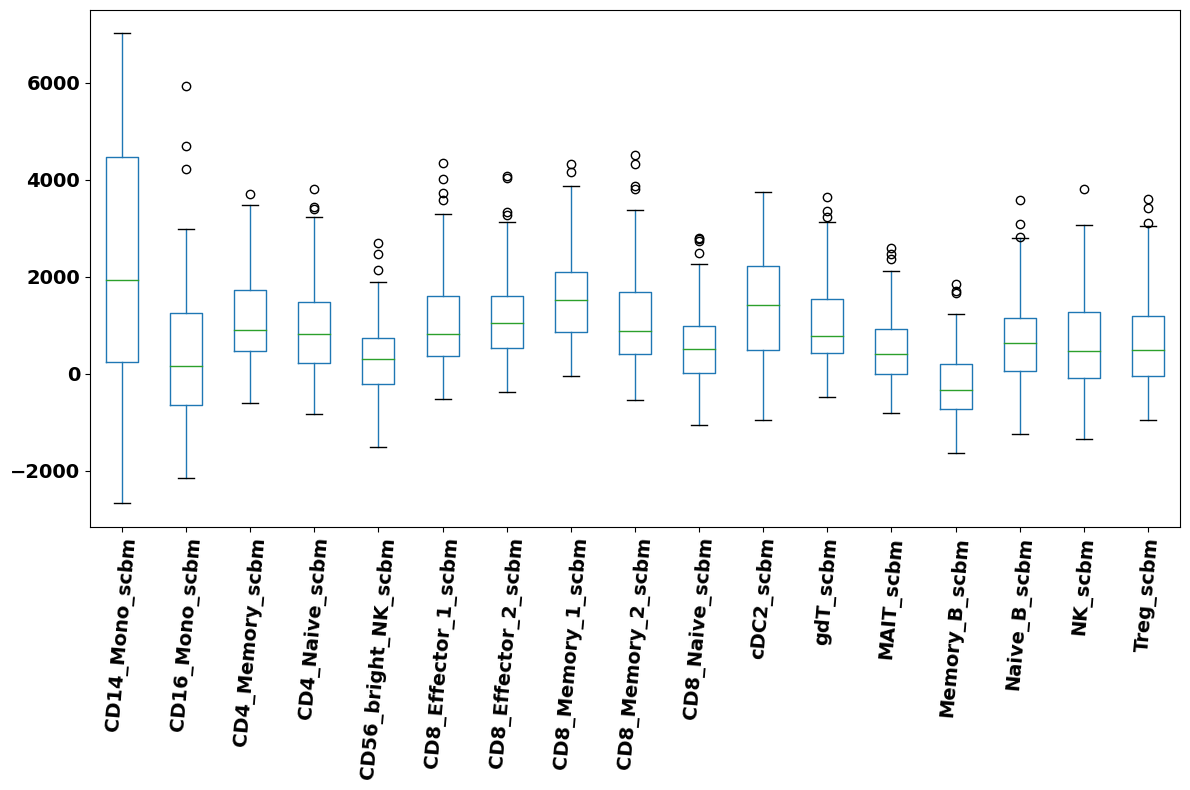

In [9]:
Output_folder = "../output/ssGSEA/"
os.makedirs(Output_folder,exist_ok=True)

plt.figure(figsize=(12,8))

ax = Discovery_ssGSEA_df.boxplot(column=list(Discovery_ssGSEA_df[GMT_immune_only].columns),rot=85)

ax.set_yticklabels(ax.get_ymajorticklabels(), fontsize = 14, style='normal',weight='bold')
ax.set_xticklabels(ax.get_xmajorticklabels(), fontsize = 14, style='normal',weight='bold')

ax.grid(False)
plt.tight_layout()
plt.savefig(Output_folder+'Discovery_cohort_Immune_only_ssGSEA_ES_boxplots.png', dpi=200)
plt.savefig(Output_folder+'Discovery_cohort_Immune_only_ssGSEA_ES_boxplots.svg')
plt.show()
plt.close()

# Cox-LASSO modelling with Cross-Validation

In [10]:
def plot_coefficients(coefs, n_highlight):
    '''
    Plot the coefficients of the penalised COX model
    as a forest plot.
    '''
    _, ax = plt.subplots(figsize=(9, 6))
    n_features = coefs.shape[0]
    alphas = coefs.columns
    for row in coefs.itertuples():
        ax.semilogx(alphas, row[1:], ".-", label=row.Index)

    alpha_min = alphas.min()
    top_coefs = coefs.loc[:, alpha_min].map(abs).sort_values().tail(n_highlight)
    for name in top_coefs.index:
        coef = coefs.loc[name, alpha_min]
        plt.text(alpha_min, coef, name + "   ", horizontalalignment="right", verticalalignment="center")

    ax.yaxis.set_label_position("right")
    ax.yaxis.tick_right()
    ax.grid(True)
    ax.set_xlabel("alpha")
    ax.set_ylabel("coefficient")

In [11]:
def Penalised_Cox_modelling_with_CV(output_folder=None,input_data=None,input_sign=None,annot_data=None,status_label=None,survival_label=None,cv_type=None,fold_num=5,l1_ratio=1):
    '''
    Run a penalised COX model with an alpha optimisation
    through grid search K-fold cross-validation.
    '''
    ### Create model output folder
    os.makedirs(output_folder,exist_ok=True)

    input_data_df = input_data.copy() # German_BM_ssGSEA_df_low_subset, German_BM_ssGSEA_df_high_subset
    input_signatures = input_sign # GMT_immune_order, GMT_sergio_order, GMT_sergio_exhaust_order, GMT_order
    annot_data_df = annot_data.copy()
    
    ### Creation of the input data for CoxLasso
    cohort_annot = pd.merge(annot_data_df, input_data_df,left_index=True,right_index=True).copy()

    cohort_annot_y = cohort_annot[[status_label,survival_label]].copy()
    v = cohort_annot_y.reset_index(drop=True)
    cohort_annot_y = np.rec.fromrecords(v, names=v.columns.tolist())

    X = cohort_annot[input_signatures].copy()
    y = cohort_annot_y.copy()
    
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)

    ### Running simple CoxLasso
    cox_lasso = CoxnetSurvivalAnalysis(l1_ratio=l1_ratio, alpha_min_ratio='auto',normalize=False)
    cox_lasso.fit(X_scaled, y)

    coefficients_lasso = pd.DataFrame(cox_lasso.coef_, index=X.columns, columns=np.round(cox_lasso.alphas_, 6))
    plot_coefficients(coefficients_lasso, n_highlight=5)

    plt.tight_layout()
    plt.savefig(output_folder+'CoxLasso_coefficients_pointplot.png', dpi=300)
    plt.savefig(output_folder+'CoxLasso_coefficients_pointplot.svg', dpi=300)
#     plt.show()
    plt.close()

    ### Optimising alpha for CoxLasso via cross-validation
    coxnet_pipe = make_pipeline(StandardScaler(), CoxnetSurvivalAnalysis(l1_ratio=l1_ratio, alpha_min_ratio='auto', max_iter=10000))
    coxnet_pipe.fit(X, y)

    estimated_alphas = coxnet_pipe.named_steps["coxnetsurvivalanalysis"].alphas_
    if cv_type == 'kfold_norm':
        cv = KFold(n_splits=fold_num, shuffle=False)
    elif cv_type == 'kfold_shuffle':
        cv = KFold(n_splits=fold_num, shuffle=True, random_state=0) # fix seed for reproducibility
    elif cv_type == 'kfold_repeat':
        cv = RepeatedKFold(n_splits=fold_num, n_repeats=5, random_state=0) # fix seed for reproducibility
    else:
        print('No such Kfold type...')
        return
    gcv = GridSearchCV(
        make_pipeline(StandardScaler(), CoxnetSurvivalAnalysis(l1_ratio=l1_ratio)),
        param_grid={"coxnetsurvivalanalysis__alphas": [[v] for v in estimated_alphas]},
        cv=cv,
        n_jobs=4,
        return_train_score=True
    ).fit(X, y)

    cv_results = pd.DataFrame(gcv.cv_results_)

    alphas = cv_results.param_coxnetsurvivalanalysis__alphas.map(lambda x: x[0])
    mean = cv_results.mean_test_score
    std = cv_results.std_test_score

    fig, ax = plt.subplots(figsize=(9, 6))
    ax.plot(alphas, mean)
    ax.fill_between(alphas, mean - std, mean + std, alpha=0.15)
    ax.set_xscale("log")
    ax.set_ylabel("concordance index")
    ax.set_xlabel("alpha")
    ax.axvline(gcv.best_params_["coxnetsurvivalanalysis__alphas"][0], c="C1")
    ax.axhline(0.5, color="grey", linestyle="--")
    ax.grid(True)

    plt.tight_layout()
    plt.savefig(output_folder+'CoxLasso_alpha_optimisation.png', dpi=300)
    plt.savefig(output_folder+'CoxLasso_alpha_optimisation.svg', dpi=300)
    # plt.show()
    plt.close()

    ### Exporting optimised model
    best_model = gcv.best_estimator_.named_steps["coxnetsurvivalanalysis"]
    best_coefs = pd.DataFrame(best_model.coef_, index=X.columns, columns=["coefficient"])
    best_coefs.to_csv(output_folder+'CoxLasso_best_fit_coefs.txt',sep='\t',index=True)

    non_zero = np.sum(best_coefs.iloc[:, 0] != 0)

    non_zero_coefs = best_coefs.query("coefficient != 0")
    coef_order = non_zero_coefs.abs().sort_values("coefficient").index

    _, ax = plt.subplots(figsize=(6, 8))
    non_zero_coefs.loc[coef_order].plot.barh(ax=ax, legend=False)
    ax.set_xlabel("coefficient")
    ax.grid(True)

    plt.tight_layout()
    plt.savefig(output_folder+'CoxLasso_coef_forestplot.png', dpi=300)
    plt.savefig(output_folder+'CoxLasso_coef_forestplot.svg', dpi=300)
    # plt.show()
    plt.close()

    ### Saving best result from fit
    pd.DataFrame.from_dict(gcv.cv_results_).iloc[gcv.best_index_].to_csv(output_folder+'CoxLasso_best_fit_result.txt',sep='\t',index=True)
    pd.DataFrame.from_dict(gcv.cv_results_).to_csv(output_folder+'CoxLasso_full_fit_result.txt',sep='\t',index=True)

    return

In [13]:
Kfold_type = 'kfold_norm' # Available algorithm for Cross-Validation (CV): kfold_norm, kfold_shuffle, kfold_repeat 
Kfold_size = 10 # Size of k-fold for CV
L1_ratio = 1 # L1/L2 ratio for CoxNet penalisation
output_folder = '../output/CoxLasso_modelling_'+str(Kfold_size)+'_'+Kfold_type+'_CV/' # Output folder of CoxLasso modelling results


Penalised_Cox_modelling_with_CV(output_folder = output_folder,
                                input_data = Discovery_ssGSEA_df,
                                input_sign = GMT_immune_only,
                                annot_data = clinical_data_df,status_label='OS',survival_label='OS.time',
                                cv_type=Kfold_type,fold_num=Kfold_size,l1_ratio=L1_ratio)

/Users/nsompairac/miniconda/lib/python3.9/site-packages/sklearn/pipeline.py:427: UserWarning: all coefficients are zero, consider decreasing alpha.
  self._final_estimator.fit(Xt, y, **fit_params_last_step)
/Users/nsompairac/miniconda/lib/python3.9/site-packages/sklearn/pipeline.py:427: UserWarning: all coefficients are zero, consider decreasing alpha.
  self._final_estimator.fit(Xt, y, **fit_params_last_step)
/Users/nsompairac/miniconda/lib/python3.9/site-packages/sklearn/pipeline.py:427: UserWarning: all coefficients are zero, consider decreasing alpha.
  self._final_estimator.fit(Xt, y, **fit_params_last_step)
/Users/nsompairac/miniconda/lib/python3.9/site-packages/sklearn/pipeline.py:427: UserWarning: all coefficients are zero, consider decreasing alpha.
  self._final_estimator.fit(Xt, y, **fit_params_last_step)
/Users/nsompairac/miniconda/lib/python3.9/site-packages/sklearn/pipeline.py:427: UserWarning: all coefficients are zero, consider decreasing alpha.
  self._final_estimator.

# MAD based immune risk groups

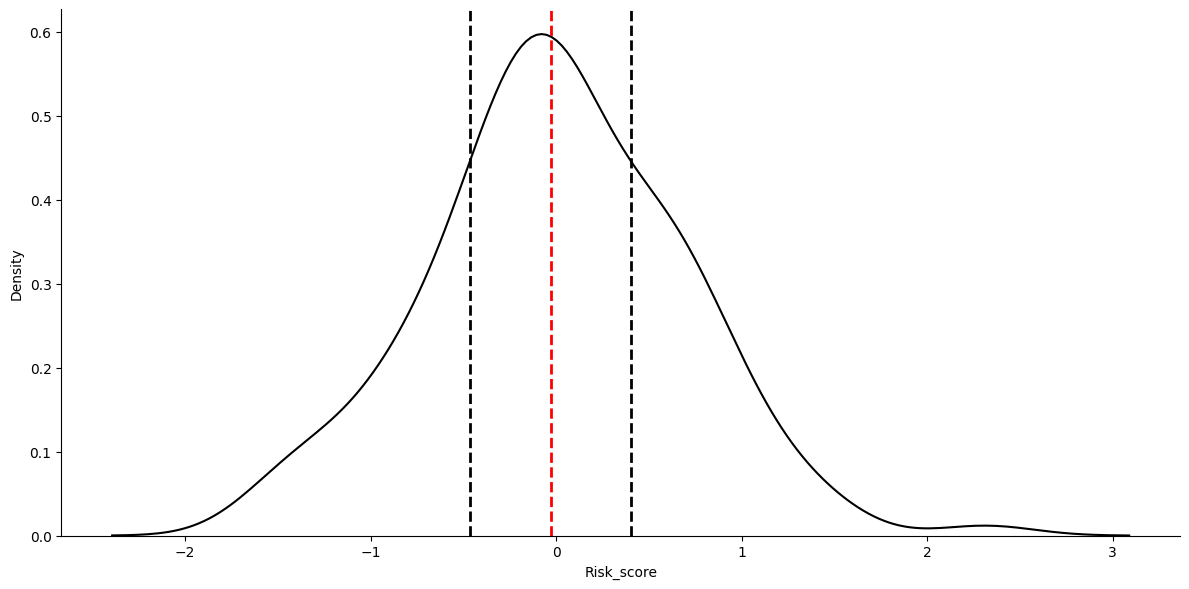

In [14]:
Output_risk_score_folder = output_folder+"Risk_score/"
os.makedirs(Output_risk_score_folder,exist_ok=True)

### Loading the CoxLasso coefficients and calculating the risk score
whole_immune_coef = pd.read_csv(output_folder+'CoxLasso_best_fit_coefs.txt',sep='\t',index_col=0)

# Rescale the ssGSEA scores as done during modelling
scaler = StandardScaler()
Discovery_ssGSEA_scalled_df = pd.DataFrame(scaler.fit_transform(Discovery_ssGSEA_df),
                                                        columns=Discovery_ssGSEA_df.columns,
                                                        index=Discovery_ssGSEA_df.index)

Discovery_ssGSEA_coef_df = Discovery_ssGSEA_scalled_df.copy()
Discovery_ssGSEA_coef_df = Discovery_ssGSEA_coef_df[whole_immune_coef.index]
for signature in Discovery_ssGSEA_coef_df.columns.values:
    Discovery_ssGSEA_coef_df[signature] = Discovery_ssGSEA_coef_df[signature] * whole_immune_coef.T[signature][0]

Discovery_ssGSEA_coef_df['Risk_score'] = Discovery_ssGSEA_coef_df.sum(axis=1)

### Plotting the immune risk score
sns.displot(data=Discovery_ssGSEA_coef_df, x='Risk_score', kind="kde",
           height=6, aspect=12/6, color='k')

plt.axvline(x=Discovery_ssGSEA_coef_df['Risk_score'].median(),ls='--', lw=2, color='r')

### Plotting the Median Absolute Deviation lines, used to separate the immune risk categories
mad = scipy.stats.median_abs_deviation(Discovery_ssGSEA_coef_df['Risk_score'])
mad_coef = 1

plt.axvline(x=Discovery_ssGSEA_coef_df['Risk_score'].median()-(mad_coef*mad),ls='--', lw=2, color='k')
plt.axvline(x=Discovery_ssGSEA_coef_df['Risk_score'].median()+(mad_coef*mad),ls='--', lw=2, color='k')

plt.tight_layout()
plt.savefig(Output_risk_score_folder+'Discovery_3_MAD_categories_risk_score_distplot.png', dpi=200)
plt.savefig(Output_risk_score_folder+'Discovery_3_MAD_categories_risk_score_distplot.svg', dpi=200)
plt.show()
plt.close()

# Visualising survival of Immune Risk Groups with Kaplan-Meier curves

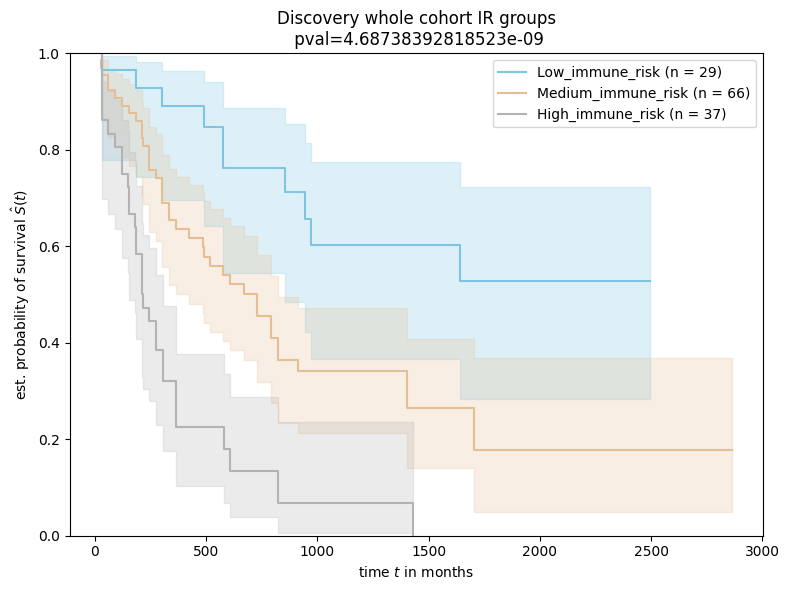

In [15]:
### Creation of output folder for figures
Output_survival_folder = output_folder+"Survival_curves/"
os.makedirs(Output_survival_folder,exist_ok=True)

### Loading of CoxLasso coefficients to generate the immune risk (IR) score
whole_immune_coef = pd.read_csv(output_folder+'CoxLasso_best_fit_coefs.txt',sep='\t',index_col=0)

# Rescale the ssGSEA scores as done during modelling
scaler = StandardScaler()
Discovery_ssGSEA_scalled_df = pd.DataFrame(scaler.fit_transform(Discovery_ssGSEA_df),
                                                        columns=Discovery_ssGSEA_df.columns,
                                                        index=Discovery_ssGSEA_df.index)

Discovery_ssGSEA_coef_df = Discovery_ssGSEA_scalled_df.copy()
Discovery_ssGSEA_coef_df = Discovery_ssGSEA_coef_df[whole_immune_coef.index]
for signature in Discovery_ssGSEA_coef_df.columns.values:
    Discovery_ssGSEA_coef_df[signature] = Discovery_ssGSEA_coef_df[signature] * whole_immune_coef.T[signature][0]

Discovery_ssGSEA_coef_df['Risk_score'] = Discovery_ssGSEA_coef_df.sum(axis=1)

comp_name = 'Risk_score'

num_cat = 'Risk_score_3_cat'

Discovery_ssGSEA_coef_df[num_cat] = 'NA'

Discovery_ssGSEA_coef_df = Discovery_ssGSEA_coef_df.sort_values(by='Risk_score', ascending=True)

### Calculating the Median Absolute Deviation (MAD) to separate patients into 3 risk categories
mad = scipy.stats.median_abs_deviation(Discovery_ssGSEA_coef_df['Risk_score'])
mad_coef = 1

Low_immune_risk_idx = Discovery_ssGSEA_coef_df.loc[Discovery_ssGSEA_coef_df['Risk_score'] <= Discovery_ssGSEA_coef_df['Risk_score'].median()-(mad_coef*mad)].index
Medium_immune_risk_idx = Discovery_ssGSEA_coef_df.loc[(Discovery_ssGSEA_coef_df['Risk_score'] > Discovery_ssGSEA_coef_df['Risk_score'].median()-(mad_coef*mad)) & (Discovery_ssGSEA_coef_df['Risk_score'] < Discovery_ssGSEA_coef_df['Risk_score'].median()+(mad_coef*mad))].index
High_immune_risk_idx = Discovery_ssGSEA_coef_df.loc[Discovery_ssGSEA_coef_df['Risk_score'] >= Discovery_ssGSEA_coef_df['Risk_score'].median()+(mad_coef*mad)].index

Discovery_ssGSEA_coef_df[num_cat][Low_immune_risk_idx] = 'Low_immune_risk'
Discovery_ssGSEA_coef_df[num_cat][Medium_immune_risk_idx] = 'Medium_immune_risk'
Discovery_ssGSEA_coef_df[num_cat][High_immune_risk_idx] = 'High_immune_risk'

Discovery_cohort_IR_groups = pd.merge(clinical_data_df, Discovery_ssGSEA_coef_df,left_index=True,right_index=True).copy()

### Plotting survival curves of IR groups in whole cohort
cat_name_list = ['Low_immune_risk', 'Medium_immune_risk', 'High_immune_risk']
risk_color = {'Low_immune_risk':'#7FC5E2',
              'Medium_immune_risk':'#E4BE95',
              'High_immune_risk':'#B3B3B3'}

tmp_annot_merged = Discovery_cohort_IR_groups.copy()

tmp_annot_merged_y = tmp_annot_merged[['OS','OS.time']].copy()
v = tmp_annot_merged_y.reset_index(drop=True)
tmp_annot_merged_y = np.rec.fromrecords(v, names=v.columns.tolist())

annot_BM_merged_plot = tmp_annot_merged.copy()

plt.figure(figsize=(8, 6))

for value in cat_name_list:

    mask = annot_BM_merged_plot[num_cat] == value

    time_cell, survival_prob_cell, conf_int = kaplan_meier_estimator(
        annot_BM_merged_plot["OS"][mask], annot_BM_merged_plot["OS.time"][mask], conf_type="log-log"
    )
    plt.step(time_cell, survival_prob_cell, where="post", label=f"{value} (n = {mask.sum()})",
            color=risk_color[value])
    plt.fill_between(time_cell, conf_int[0], conf_int[1], alpha=0.25, step="post",color=risk_color[value])

plt.ylim(0, 1)
plt.ylabel("est. probability of survival $\hat{S}(t)$")
plt.xlabel("time $t$ in months")
plt.legend(loc="best")

group_indicator = annot_BM_merged_plot.loc[:, num_cat]
tmp_annot_merged_y_tmp = tmp_annot_merged_y[group_indicator != 'NA'].copy()

group_indicator = group_indicator.loc[group_indicator != 'NA']
chisq, pvalue, stats, covar = compare_survival(
        tmp_annot_merged_y_tmp, group_indicator, return_stats=True)

plt.title('Discovery whole cohort IR groups\n pval='+str(pvalue))
plt.tight_layout()
plt.savefig(Output_survival_folder+'Discovery_whole_cohort_3_IR_groups_survival_curve.png', dpi=200)
plt.savefig(Output_survival_folder+'Discovery_whole_cohort_3_IR_groups_survival_curve.svg', dpi=200)
plt.show()
plt.close()

# Exporting risk scores and IR groups annotations

In [16]:
Output_IR_groups_folder = output_folder+"Tables/"
os.makedirs(Output_IR_groups_folder,exist_ok=True)

Discovery_cohort_IR_groups['Risk_score'].to_csv(Output_IR_groups_folder+'Discovery_cohort_risk_scores_whole_cohort.txt',sep='\t',index=True)

Discovery_cohort_IR_groups.drop('_PATIENT',axis=1).to_csv(Output_IR_groups_folder+'Discovery_cohort_IR_groups_whole_cohort.txt',sep='\t',index=True)